# Minority-class errors and saved inference

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Previously observed TASTY holdout
These are existing TASTY holdout aggregates, not new inference. The same test was observed in prior rounds; scores are retrospective. Precision/recall differences expose minority-class failures that accuracy hides.

,precision,recall,f1-score,support
class,,,,
constant,0.500000,0.500000,0.500000,6.0
cubic,0.714286,0.714286,0.714286,7.0
linear,0.844311,0.898089,0.870370,157.0
logn,0.500000,0.400000,0.444444,5.0
nlogn,0.846154,0.423077,0.564103,26.0
quadratic,0.794872,0.837838,0.815789,74.0


Calibration: uncalibrated model scores
Checkpoint SHA256: e61c138907645ca751a8d130dd2471fc359abc6edb0827728086ce3f3bd0e6cf


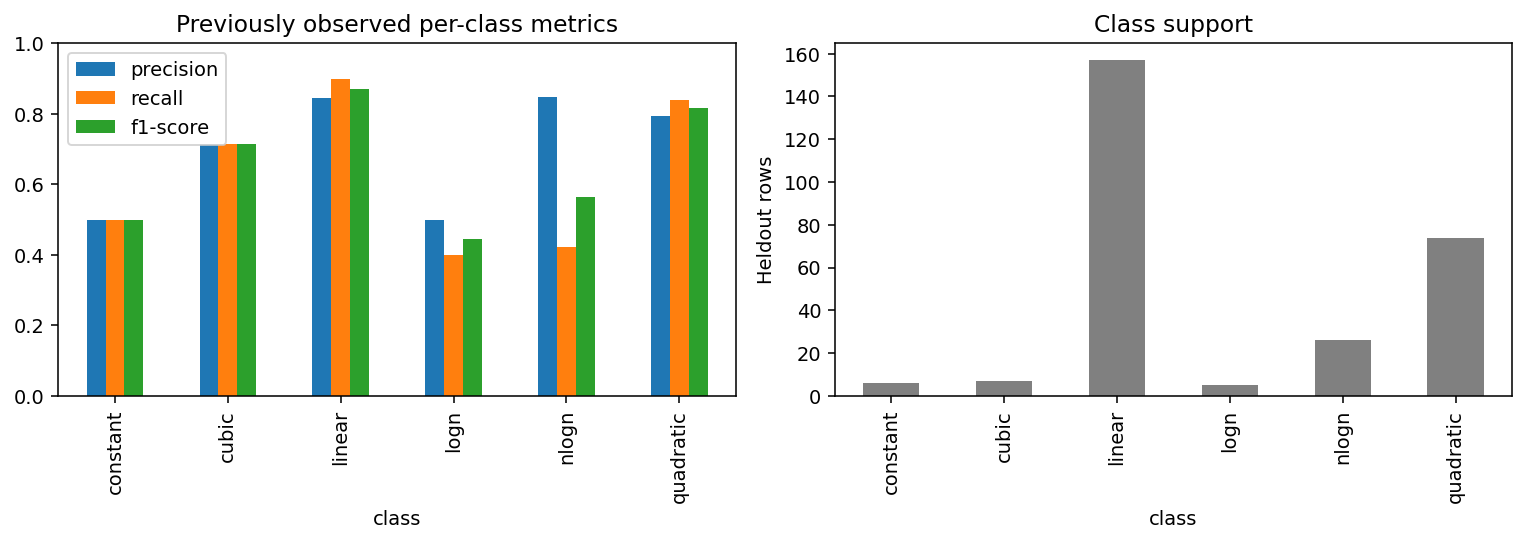

In [2]:
evaluation = read_json('models/structure-v2-weights/evaluation.json')
report = evaluation['classification_report']
rows = [{'class':label,**values} for label,values in report.items() if isinstance(values,dict) and 'support' in values and label not in ['macro avg','weighted avg']]
classes = pd.DataFrame(rows).set_index('class')
display(classes)
print('Calibration:', evaluation['calibration'])
print('Checkpoint SHA256:', evaluation['checkpoint_sha256'])
fig, axes = plt.subplots(1,2,figsize=(11,4))
classes[['precision','recall','f1-score']].plot.bar(ax=axes[0])
axes[0].set(ylim=(0,1),title='Previously observed per-class metrics')
classes.support.plot.bar(ax=axes[1],color='gray')
axes[1].set(title='Class support',ylabel='Heldout rows')
show_figure(fig,'complexity_minority_errors')

## Validation-to-test caution
A retained model can have different macro-F1 between splits simply because minority support and source families differ. No candidate is chosen by this comparison.

In [3]:
history = read_json('models/structure-v2-weights/results.json')
display(pd.json_normalize(history['compatible_observed_test_comparison']))
family = read_json('models/family-weight-v4/results.json')
for row in family['runs']:
    per_class = row['oof']['classification_report']
    rare = {label:values['recall'] for label,values in per_class.items() if isinstance(values,dict) and values.get('support',1000)<50 and label not in ['macro avg','weighted avg']}
    print(row['candidate'], 'OOF rare-class recall:', rare)

,legacy_structure_weight25.accuracy,legacy_structure_weight25.macro_f1,legacy_structure_weight25.log_loss,legacy_structure_weight25.multiclass_brier,legacy_balanced_C16.accuracy,legacy_balanced_C16.macro_f1,legacy_balanced_C16.log_loss,legacy_balanced_C16.multiclass_brier,legacy_unweighted_C4.accuracy,legacy_unweighted_C4.macro_f1,legacy_unweighted_C4.log_loss,legacy_unweighted_C4.multiclass_brier
0,0.814545,0.651499,0.578231,0.281529,0.709091,0.37901,0.762208,0.402372,0.738182,0.388322,0.758976,0.395713


v2_baseline OOF rare-class recall: {'constant': 0.14285714285714285, 'cubic': 0.42857142857142855, 'logn': 0.4}
family_v2 OOF rare-class recall: {'constant': 0.14285714285714285, 'cubic': 0.38095238095238093, 'logn': 0.4}
family_class_v2 OOF rare-class recall: {'constant': 0.14285714285714285, 'cubic': 0.47619047619047616, 'logn': 0.4}
family_mechanics_leaf3 OOF rare-class recall: {'constant': 0.14285714285714285, 'cubic': 0.47619047619047616, 'logn': 0.4}


## Production inference on a public example
This scalar/example output is permitted public inference, not a corpus prediction table. The notebook never serializes private row-level predictions.

In [4]:
from src.models.predict_model import predict
model_path = Path(os.environ.get('COMPLEXITY_MODEL','models/structure-v2-weights'))
if (model_path/'model.joblib').exists():
    result = predict(Path('examples/linear.cpp').read_text(encoding='utf-8'),model_path)
    display(pd.DataFrame({'score':result['scores']}).sort_values('score',ascending=False))
    print(result['warning'])
else:
    print('Weights are ignored; set COMPLEXITY_MODEL to a locally trained checkpoint directory.')

,score
linear,0.720247
quadratic,0.153896
logn,0.043663
nlogn,0.039237
constant,0.027205
cubic,0.015751


Statistical estimate, not a proof. Scores are uncalibrated. Input-size and execution assumptions require human review.
